# Run the full pipeline on Google Colab

1. Upload the whole project folder (including `data/raw/` with the TCIA zip unzipped and the `.xlsx`) to your Google Drive.
2. *Runtime > Change runtime type > T4 GPU*.
3. Run the cells in order.

> Course prototype for research and educational purposes. Not a medical device. Not for clinical use.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
# Change this to where the project folder is in your Drive
%cd /content/drive/MyDrive/EXSU500-Testing
!ls

/content/drive/MyDrive/EXSU500-Testing
data		    MODEL_CARD.md  outputs    requirements.txt
GETTING_STARTED.md  notebooks	   README.md  src


In [ ]:
!pip install -q -r requirements.txt
import torch; print('GPU available:', torch.cuda.is_available())

GPU available: True


## Steps 1–2: prepare data and splits
`02_make_splits.py` does nothing if `data/processed/splits.csv` already exists, which is what we want.

In [ ]:
!python src/01_prepare_data.py
!python src/02_make_splits.py

Spreadsheet: BrEaST-Lesions-USG-clinical-data-Dec-15-2023.xlsx  (256 rows)
Image folder: /content/drive/MyDrive/EXSU500-Testing/data/raw/BrEaST-Lesions_USG-images_and_masks

All cases by class:
Classification
benign       154
malignant     98
normal         4

Kept 252 lesions: 98 malignant, 154 benign (38.9% malignant)
Image size: height 289–618 px, width 363–1024 px

Reference standard:
Classification               benign  malignant
Verification                                  
confirmed by biopsy              99         98
confirmed by follow-up care      55          0

BI-RADS vs final class:
Classification  benign  malignant
BIRADS                           
2                   30          0
3                   37          0
4a                  43          1
4b                  30         16
4c                   8         41
5                    6         40

Age: median 55, range 18–87, missing 41

Saved /content/drive/MyDrive/EXSU500-Testing/data/processed/metadata.csv
/content

In [ ]:
from pathlib import Path
import shutil

if not Path("reference_outputs").exists():
    shutil.copytree("outputs", "reference_outputs")
    print("Teammate's results backed up.")
else:
    print("Backup already exists.")

Teammate's results backed up.


## Steps 3–4: baseline and classical models (cross-validation only)

In [ ]:
!python src/03_baseline.py
!python src/04_classical_ml.py

Saved /content/drive/MyDrive/EXSU500-Testing/data/processed/features.csv

[baseline_majority] cross-validation (out-of-fold, n=201)
  AUROC 0.500 (0.500–0.500)   AUPRC 0.388 (0.323–0.463)
  per-fold AUROC 0.500 ± 0.000
  threshold for sensitivity ≥ 90%: 0.388 → sens 1.00, spec 0.00

[baseline_logreg] cross-validation (out-of-fold, n=201)
  AUROC 0.750 (0.684–0.816)   AUPRC 0.655 (0.545–0.772)
  per-fold AUROC 0.750 ± 0.027
  threshold for sensitivity ≥ 90%: 0.295 → sens 0.94, spec 0.37
17 features: area_cm2, depth_width_ratio, circularity, solidity, eccentricity, extent, mean_in, std_in, skew_in, kurt_in, contrast_vs_surround, posterior_ratio, glcm_contrast, glcm_dissimilarity, glcm_homogeneity, glcm_energy, glcm_correlation

== random_forest
  best params {'clf__max_depth': 3, 'clf__max_features': 'sqrt', 'clf__min_samples_leaf': 5}  (mean CV AUROC 0.827)

[random_forest] cross-validation (out-of-fold, n=201)
  AUROC 0.825 (0.763–0.880)   AUPRC 0.725 (0.616–0.838)
  per-fold AUROC 0.8

## Step 5: CNN (about 20–40 min on a T4)
If the session disconnects, run the cell again: finished folds are reloaded from `outputs/checkpoints/`.

In [ ]:
!python src/05_cnn.py --gradcam

Device: cuda. Input: crop. Seeds: [0, 1, 2]
Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100% 44.7M/44.7M [00:00<00:00, 129MB/s]
seed 0 fold 0: val AUROC 0.870 at epoch 3
seed 0 fold 1: val AUROC 0.856 at epoch 23
seed 0 fold 2: val AUROC 0.963 at epoch 2
seed 0 fold 3: val AUROC 0.883 at epoch 13
seed 0 fold 4: val AUROC 0.867 at epoch 5
seed 1 fold 0: val AUROC 0.833 at epoch 7
seed 1 fold 1: val AUROC 0.867 at epoch 3
seed 1 fold 2: val AUROC 0.899 at epoch 1
seed 1 fold 3: val AUROC 0.854 at epoch 2
seed 1 fold 4: val AUROC 0.885 at epoch 8
seed 2 fold 0: val AUROC 0.877 at epoch 27
seed 2 fold 1: val AUROC 0.840 at epoch 18
seed 2 fold 2: val AUROC 0.891 at epoch 1
seed 2 fold 3: val AUROC 0.862 at epoch 20
seed 2 fold 4: val AUROC 0.841 at epoch 9

Grad-CAM check (seed 0, all validation folds, n=201): 42% of heatmap mass lies inside the lesion outline, which covers 35% of the input on average 

## Step 6: compare models

### Cross-validation (out-of-fold, train/validation set)

Values are point estimates with 95% bootstrap confidence intervals. Threshold chosen on cross-validation for sensitivity ≥ 0.90.

| Model             | AUROC               | AUPRC               | Sensitivity         | Specificity         |   Brier |   Threshold |
|:------------------|:--------------------|:--------------------|:--------------------|:--------------------|--------:|------------:|
| baseline_majority | 0.500 (0.500–0.500) | 0.388 (0.323–0.463) | 1.000 (1.000–1.000) | 0.000 (0.000–0.000) |   0.237 |       0.388 |
| baseline_logreg   | 0.750 (0.684–0.816) | 0.655 (0.545–0.772) | 0.936 (0.878–0.987) | 0.374 (0.290–0.462) |   0.202 |       0.295 |
| random_forest     | 0.825 (0.763–0.880) | 0.725 (0.616–0.838) | 0.910 (0.843–0.970) | 0.439 (0.355–0.530) |   0.172 |       0.299 |
| svm               | 0.834 (0.773–0.887) | 0.763 (0.664–0.858) | 0.923 (0.859–0.975) | 0.520 (0.435–0.608) |   0.16  |       0.224 |
| cnn_re

### Cross-validation (out-of-fold, train/validation set)

Values are point estimates with 95% bootstrap confidence intervals. Threshold chosen on cross-validation for sensitivity ≥ 0.90.

| Model             | AUROC               | AUPRC               | Sensitivity         | Specificity         |   Brier |   Threshold |
|:------------------|:--------------------|:--------------------|:--------------------|:--------------------|--------:|------------:|
| baseline_majority | 0.500 (0.500–0.500) | 0.388 (0.323–0.463) | 1.000 (1.000–1.000) | 0.000 (0.000–0.000) |   0.237 |       0.388 |
| baseline_logreg   | 0.750 (0.684–0.816) | 0.655 (0.545–0.772) | 0.936 (0.878–0.987) | 0.374 (0.290–0.462) |   0.202 |       0.295 |
| random_forest     | 0.825 (0.763–0.880) | 0.725 (0.616–0.838) | 0.910 (0.843–0.970) | 0.439 (0.355–0.530) |   0.172 |       0.299 |
| svm               | 0.834 (0.773–0.887) | 0.763 (0.664–0.858) | 0.923 (0.859–0.975) | 0.520 (0.435–0.608) |   0.16  |       0.224 |
| cnn_resnet18_crop | 0.867 (0.810–0.917) | 0.811 (0.720–0.891) | 0.910 (0.842–0.970) | 0.577 (0.488–0.661) |   0.149 |       0.29  |

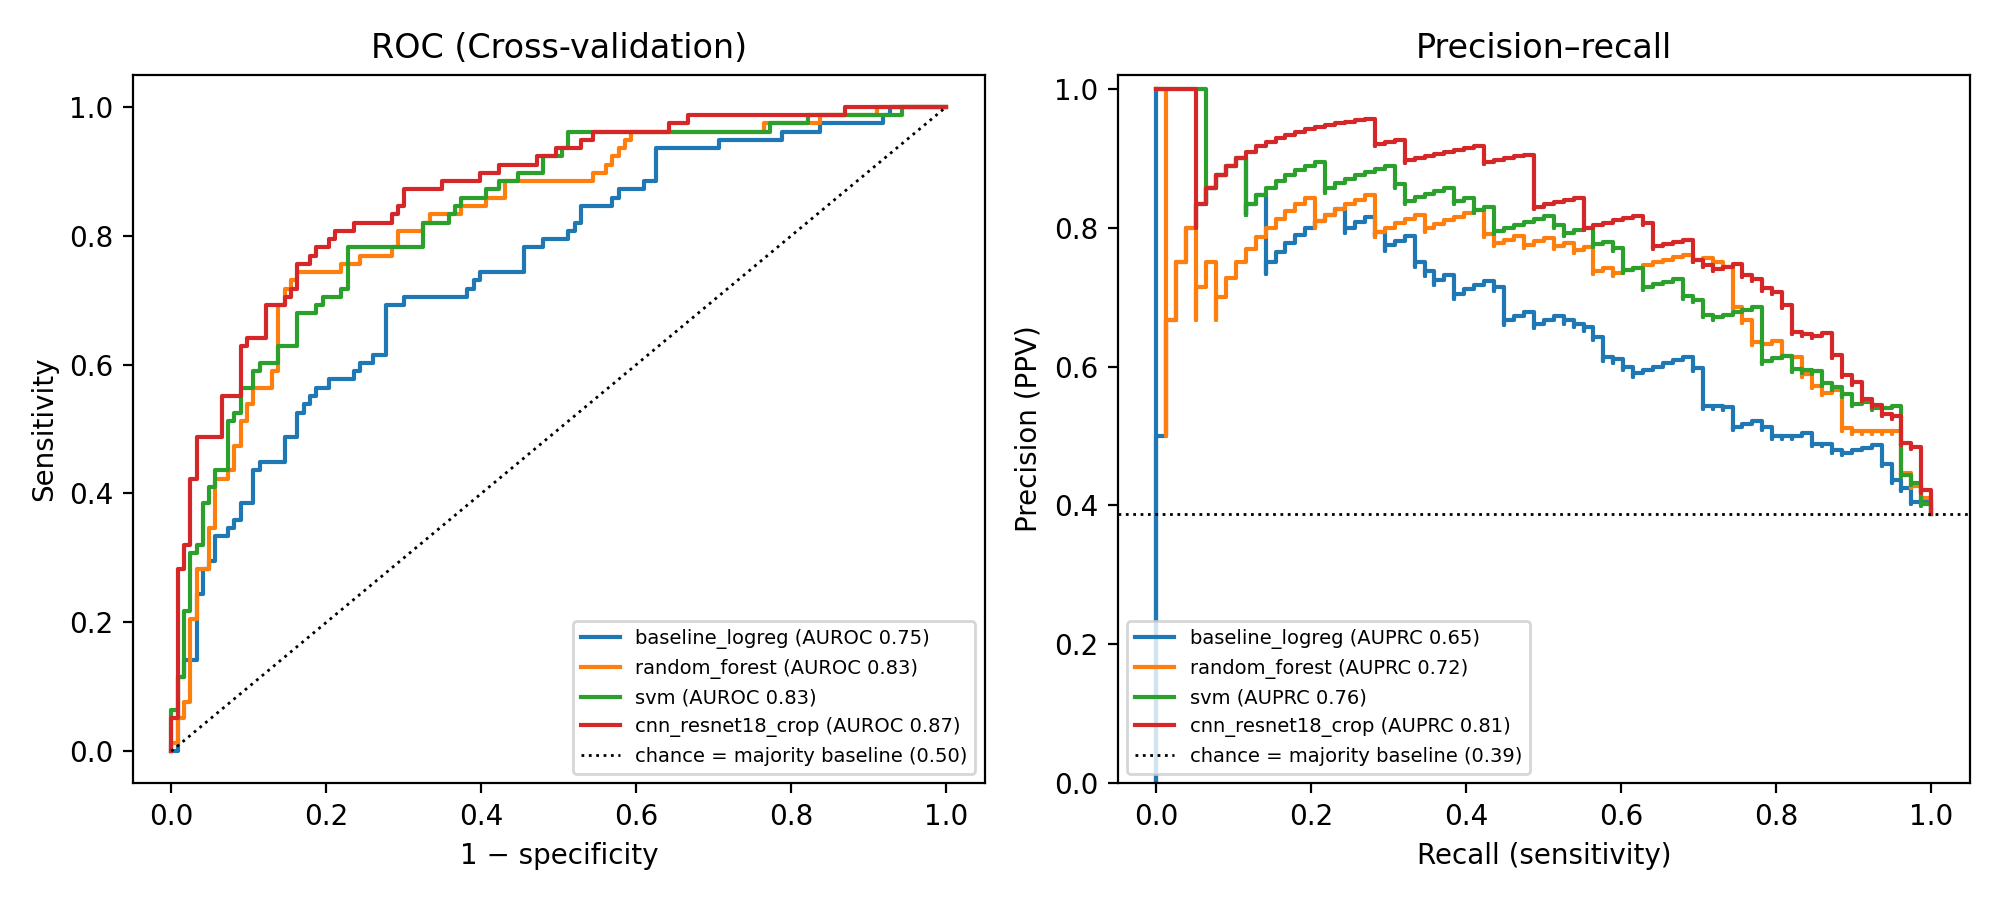

In [ ]:
!python src/06_compare_models.py
from IPython.display import Image, Markdown, display
display(Markdown(open('outputs/results/comparison_cv.md').read()))
display(Image('outputs/figures/roc_pr_cv.png'))

## Final test-set evaluation — run ONCE, only when the team agrees every model is frozen
Remove the `#` signs to run.

In [ ]:
# !python src/03_baseline.py --final
# !python src/04_classical_ml.py --final
# !python src/05_cnn.py --final --gradcam
# !python src/06_compare_models.py --final

## Record the exact package versions (for the requirements file)

In [ ]:
!pip freeze | grep -iE '^(numpy|pandas|openpyxl|pillow|scipy|scikit-learn|scikit-image|matplotlib|tabulate|torch|torchvision)==' > requirements-lock.txt
!cat requirements-lock.txt

matplotlib==3.10.0
numpy==2.4.6
openpyxl==3.1.5
pandas==2.2.3
pillow==11.3.0
scikit-image==0.25.2
scikit-learn==1.6.1
scipy==1.16.3
tabulate==0.9.0
torch==2.14.1+cu130
torchvision==0.29.1+cu130
